In [1]:
!pip install -q pytorch-lightning rdkit torch_geometric deepchem
!pip install -q -U scikit-learn
!pip install -q PyTDC --no-deps
!pip install -q fuzzywuzzy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 552.4/552.4 kB 10.2 MB/s  0:00:00


In [6]:
import numpy as np
import pandas as pd
import torch
import pytorch_lightning as pl

pl.seed_everything(0)

print("GPU:", torch.cuda.get_device_name(0))

INFO:lightning_fabric.utilities.seed:Seed set to 0


GPU: Tesla T4


In [7]:
#adapted from intro_to_gnns
from tqdm import tqdm
import pandas as pd
from torch_geometric.data import Data, InMemoryDataset
from tdc.single_pred import Tox
import deepchem as dc


def get_featurizer(name):
    return dc.feat.MolGraphConvFeaturizer(use_edges=True)


class HergGraphData(InMemoryDataset):
    """The hERG_Karim graph dataset using PyG
    """
    def __init__(self, root, featurizer='molgraphconv', transform=None):
        self.featurizer = featurizer
        super().__init__(root, transform)
        self.data, self.slices = torch.load(self.processed_paths[0], weights_only=False)

    @property
    def raw_file_names(self):
        return ['herg_karim_scaffold.csv']

    @property
    def processed_file_names(self):
        return [f'data_{self.featurizer}.pt']

    def download(self):
        print('Downloading hERG_Karim dataset...')
        data = Tox(name='hERG_Karim', path=self.raw_dir)
        split = data.get_split(method='scaffold', frac=[0.7, 0.15, 0.15], seed=42)
        df = pd.concat([split[name].assign(split=name) for name in ['train', 'valid', 'test']])
        df.to_csv(self.raw_paths[0], index=False)

    def process(self):
        df = pd.read_csv(self.raw_paths[0])
        smiles = df['Drug'].values.tolist()
        target = df['Y'].values.tolist()

        print(f'Converting SMILES strings into graphs ({self.featurizer})...')
        graphs = get_featurizer(self.featurizer).featurize(smiles)

        data_list = []
        for i, graph in enumerate(tqdm(graphs)):
            if not hasattr(graph, 'node_features') or graph.num_edges == 0:
                continue
            x = torch.tensor(graph.node_features, dtype=torch.float)
            edge_index = torch.tensor(graph.edge_index, dtype=torch.long)
            edge_attr = torch.tensor(graph.edge_features, dtype=torch.float)
            y = torch.tensor([target[i]], dtype=torch.float)
            data_list.append(Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=y,
                                  smiles=smiles[i]))

        print(f'{len(smiles) - len(data_list)} molecules skipped')
        torch.save(self.collate(data_list), self.processed_paths[0])

wandb: WARNING W&B installed but not logged in.  Run `wandb login` or set the WANDB_API_KEY env variable.
Instructions for updating:
experimental_relax_shapes is deprecated, use reduce_retracing instead
wandb: WARNING W&B installed but not logged in.  Run `wandb login` or set the WANDB_API_KEY env variable.


In [8]:
dataset = HergGraphData('./herg_pyg_dc', featurizer='molgraphconv')

df = pd.read_csv(dataset.raw_paths[0])
split_of = dict(zip(df['Drug'], df['split']))
splits = np.array([split_of[d.smiles] for d in dataset])

train_dataset = dataset[np.where(splits == 'train')[0]]
valid_dataset = dataset[np.where(splits == 'valid')[0]]
test_dataset = dataset[np.where(splits == 'test')[0]]
print(f"Train: {len(train_dataset)}, Valid: {len(valid_dataset)}, Test: {len(test_dataset)}")
print(f"Atom features: {dataset.num_node_features}, bond features: {dataset.num_edge_features}")

Downloading...


100%|██████████| 885k/885k [00:00<00:00, 2.99MiB/s]
Loading...
Done!
100%|██████████| 13445/13445 [00:07<00:00, 1802.36it/s]
Processing...


Converting SMILES strings into graphs (molgraphconv)...


100%|██████████| 13445/13445 [00:01<00:00, 10455.89it/s]


0 molecules skipped


Done!


Train: 9411, Valid: 2016, Test: 2018
Atom features: 30, bond features: 11


In [10]:
#adapted from intro_to_gnns
import torch.nn.functional as F
from torch.nn import GRU, Linear
from torch_geometric.loader import DataLoader
from torch_geometric.nn import NNConv, MLP, global_add_pool
from sklearn.metrics import roc_auc_score


class MPNN(pl.LightningModule):
    def __init__(self, hidden_dim, out_dim,
                 train_data, valid_data, test_data,
                 batch_size=32, lr=1e-3, num_steps=4, dropout=0.1):
        super().__init__()
        self.train_data = train_data
        self.valid_data = valid_data
        self.test_data = test_data
        self.batch_size = batch_size
        self.lr = lr
        self.num_steps = num_steps
        self.val_probs, self.val_labels = [], []

        self.atom_emb = Linear(train_data.num_node_features, hidden_dim)
        self.bond_emb = Linear(train_data.num_edge_features, hidden_dim)

        nn = MLP([hidden_dim, hidden_dim*2, hidden_dim*hidden_dim])
        self.conv = NNConv(hidden_dim, hidden_dim, nn, aggr='mean')
        self.gru = GRU(hidden_dim, hidden_dim)
        # Readout layers
        self.mlp = MLP([hidden_dim, int(hidden_dim/2), out_dim], dropout=dropout)

    def forward(self, data, mode="train"):

        # Initialization
        x = self.atom_emb(data.x)
        h = x.unsqueeze(0)
        edge_attr = self.bond_emb(data.edge_attr)

        # Message passing
        for i in range(self.num_steps):
            m = F.relu(self.conv(x, data.edge_index, edge_attr))
            x, h = self.gru(m.unsqueeze(0), h)
            x = x.squeeze(0)

        # Readout
        x = global_add_pool(x, data.batch)
        x = self.mlp(x)

        return x.view(-1)
    def training_step(self, batch, batch_idx):
        out = self.forward(batch, mode="train")
        loss = F.binary_cross_entropy_with_logits(out, batch.y)
        self.log("Train loss", loss, batch_size=batch.num_graphs)
        return loss

    def validation_step(self, batch, batch_idx):
        out = self.forward(batch, mode="valid")
        loss = F.binary_cross_entropy_with_logits(out, batch.y)
        self.log("Valid loss", loss, batch_size=batch.num_graphs)
        self.val_probs.append(torch.sigmoid(out).cpu())
        self.val_labels.append(batch.y.cpu())

    def on_validation_epoch_end(self):
        probs = torch.cat(self.val_probs).numpy()
        labels = torch.cat(self.val_labels).numpy()
        self.val_probs, self.val_labels = [], []
        if self.trainer.sanity_checking:
            return
        self.log("Valid ROC-AUC", roc_auc_score(labels, probs), prog_bar=True)

    def test_step(self, batch, batch_idx):
        out = self.forward(batch, mode="test")
        loss = F.binary_cross_entropy_with_logits(out, batch.y)
        self.log("Test loss", loss, batch_size=batch.num_graphs)

    def configure_optimizers(self):
        optimizer = torch.optim.Adam(self.parameters(), lr=self.lr, weight_decay=1e-5)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max',
                                                               factor=0.5, patience=5)
        return {"optimizer": optimizer,
                "lr_scheduler": {"scheduler": scheduler, "monitor": "Valid ROC-AUC"}}

    def train_dataloader(self):
        return DataLoader(self.train_data, batch_size=self.batch_size, shuffle=True)

    def val_dataloader(self):
        return DataLoader(self.valid_data, batch_size=self.batch_size, shuffle=False)

    def test_dataloader(self):
        return DataLoader(self.test_data, batch_size=self.batch_size, shuffle=False)

In [11]:
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping

#some improveements to architechture: hidden_dim 64 -> 128, 4 message passing steps (instead of 3),
#added dropout in the readout
gnn_model = MPNN(
    hidden_dim=128,
    out_dim=1,
    train_data=train_dataset,
    valid_data=valid_dataset,
    test_data=test_dataset,
    lr=0.001,
    batch_size=64,
    num_steps=4,
    dropout=0.1
)

checkpoint = ModelCheckpoint(dirpath='herg_checkpoints', monitor='Valid ROC-AUC', mode='max')
early_stop = EarlyStopping(monitor='Valid ROC-AUC', mode='max', patience=20)

trainer = pl.Trainer(max_epochs=100, accelerator='auto', devices=1,
                     callbacks=[checkpoint, early_stop], logger=False)
trainer.fit(model=gnn_model)

print(f"Best validation ROC-AUC: {checkpoint.best_model_score.item():.3f}")

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name     ┃ Type   ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ atom_emb │ Linear │  4.0 K │ train │     0 │
│ 1 │ bond_emb │ Linear │  1.5 K │ train │     0 │
│ 2 │ conv     │ NNConv │  4.3 M │ train │     0 │
│ 3 │ gru      │ GRU    │ 99.1 K │ train │     0 │
│ 4 │ mlp      │ MLP    │  8.4 K │ train │     0 │
└───┴──────────┴────────┴────────┴───────┴───────┘

Trainable params: 4.4 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 4.4 M                                                                                                
Total estimated model params size (MB): 17.495                                                                     
Modules in train mode: 22                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

Best validation ROC-AUC: 0.834


In [13]:
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, matthews_corrcoef

def predict(dataset):
    loader = DataLoader(dataset, batch_size=256, shuffle=False)
    logits = torch.cat(trainer.predict(gnn_model, dataloaders=loader, ckpt_path="best"))
    y_prob = torch.sigmoid(logits).cpu().numpy()
    y_true = torch.cat([d.y for d in dataset]).numpy().astype(int)
    return y_true, y_prob

def report(name, y_true, y_prob):
    y_pred = (y_prob >= 0.5).astype(int)
    print(f"{name}")
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.3f}")
    print(f"ROC-AUC: {roc_auc_score(y_true, y_prob):.3f}")
    print(f"F1: {f1_score(y_true, y_pred):.3f}")
    print(f"MCC: {matthews_corrcoef(y_true, y_pred):.3f}")

In [14]:
y_val_true, y_val_prob = predict(valid_dataset)
y_test_true, y_test_prob = predict(test_dataset)

report("MPNN (validation)", y_val_true, y_val_prob)
report("MPNN (test)", y_test_true, y_test_prob)

INFO:pytorch_lightning.utilities.rank_zero:Restoring states from the checkpoint path at /content/herg_checkpoints/epoch=31-step=4736.ckpt
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.utilities.rank_zero:Loaded model weights from the checkpoint at /content/herg_checkpoints/epoch=31-step=4736.ckpt


Output()

INFO:pytorch_lightning.utilities.rank_zero:Restoring states from the checkpoint path at /content/herg_checkpoints/epoch=31-step=4736.ckpt
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.utilities.rank_zero:Loaded model weights from the checkpoint at /content/herg_checkpoints/epoch=31-step=4736.ckpt


Output()

MPNN (validation)
Accuracy: 0.727
ROC-AUC: 0.834
F1: 0.774
MCC: 0.479
MPNN (test)
Accuracy: 0.716
ROC-AUC: 0.851
F1: 0.761
MCC: 0.475


Was interested to see, which the model most confidentally missclassifies as hERG blockers.

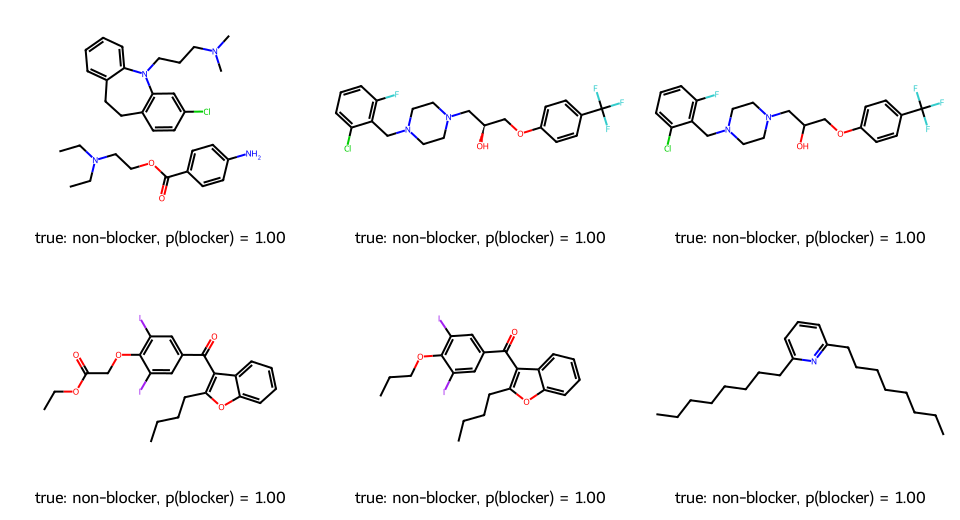

In [15]:
from rdkit import Chem
from rdkit.Chem import Draw

errors = np.abs(y_test_true - y_test_prob)
worst = np.argsort(errors)[::-1][:6]

mols, legends = [], []
for i in worst:
    data = test_dataset[int(i)]
    mols.append(Chem.MolFromSmiles(data.smiles))
    true_label = 'blocker' if y_test_true[i] == 1 else 'non-blocker'
    legends.append(f"true: {true_label}, p(blocker) = {y_test_prob[i]:.2f}")

Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(320, 260), legends=legends)

In [18]:
best_model = MPNN.load_from_checkpoint(checkpoint.best_model_path,
                                       hidden_dim=128, out_dim=1,
                                       num_steps=4, dropout=0.1,
                                       train_data=train_dataset,
                                       valid_data=valid_dataset,
                                       test_data=test_dataset)

torch.save(best_model.state_dict(), 'mpnn_herg_molgraphconv.pt')